# Diffusion models and ODE generation
## A simple flow-matching example with four Gaussian components

We will turn samples from a standard Gaussian into samples resembling a **four-component Gaussian mixture** in two dimensions. The four centers are $(-2,-2)$, $(-2,2)$, $(2,-2)$, and $(2,2)$. Each generated sample is a point with two coordinates.

**Which method are we implementing?** We use **flow matching with straight interpolation paths**, an especially simple way to train a generative ODE. It is closely related to the first rectified-flow training step. This is not a DDPM or a stochastic diffusion simulation. Diffusion models can also generate with a probability-flow ODE, but they learn a different quantity (a score) and construct the ODE differently. We explain that connection at the end.

The order is **data → architecture → training targets and loss → training → ODE sampling → evaluation**. No external dataset or GPU is needed. The code uses PyTorch and Matplotlib. Run all cells in order, with this folder as the working directory. Restart the kernel before repeating an experiment. The saved notebook includes executed outputs; `README.txt` gives setup instructions.

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(7)
torch.set_num_threads(1)
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 12})

## 1. Create the target data

First choose a center uniformly, then add independent Gaussian noise to its two coordinates:

$$C\sim\mathrm{Uniform}\{1,2,3,4\},\qquad
X_1=\mu_C+0.35\varepsilon,\qquad\varepsilon\sim\mathcal N(0,I_2).$$

Equivalently,

$$p_{\mathrm{data}}(x)=\frac14\sum_{j=1}^4\mathcal N(x;\mu_j,0.35^2I_2).$$

Each component has weight $1/4$, mean $\mu_j$, and covariance $0.35^2I_2$. A center is the middle of a cluster, not its only possible value. The training set contains 4,096 points, with shape `(4096, 2)`.

We know the sampling rule so we can create and check this controlled example. Direct sampling already solves this known mixture; the purpose here is to teach how a model learns from samples. The network will not receive a component label, center, or mixture density as an input.

In [2]:
centers = torch.tensor([[-2., -2.], [-2., 2.], [2., -2.], [2., 2.]])
sigma = 0.35

def sample_data(n):
    labels = torch.randint(4, (n,))
    return centers[labels] + sigma * torch.randn(n, 2)

x_train = sample_data(4096)

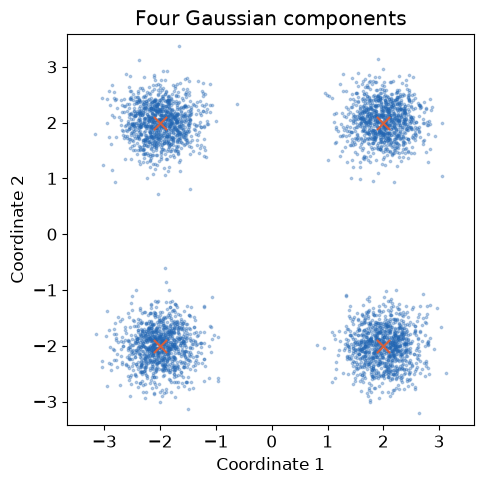

In [3]:
plt.figure(figsize=(5, 5))
plt.scatter(x_train[:, 0], x_train[:, 1], s=3, alpha=0.3, color="#2266B3")
plt.scatter(centers[:, 0], centers[:, 1], marker="x", s=90, color="#D6603C")
plt.xlabel("Coordinate 1")
plt.ylabel("Coordinate 2")
plt.title("Four Gaussian components")
plt.axis("equal")
plt.tight_layout()
plt.savefig("figures/training_data.pdf")
plt.show()

## 2. Learn a velocity field

An ordinary differential equation (ODE) moves a point according to

$$\frac{dX(t)}{dt}=v_\theta(X(t),t),\qquad X(0)\sim\mathcal N(0,I_2).$$

The network receives the current **position** $(x^{(1)},x^{(2)})$ and the current **generation time** $t$. Its two outputs describe velocity in the two coordinate directions. A velocity is an instantaneous rate of motion, not a final sample or a probability.

Our convention is **$t=0$ for noise and $t=1$ for data**. This time is an artificial interpolation parameter. It is not physical time or an index in a time series.

The architecture has three inputs, two hidden layers of width 64, and two outputs: **4,546 trainable parameters**. `SiLU` is the smooth activation $\operatorname{SiLU}(a)=a\sigma(a)$. We use one network and one optimizer.

In [4]:
model = nn.Sequential(
    nn.Linear(3, 64),
    nn.SiLU(),
    nn.Linear(64, 64),
    nn.SiLU(),
    nn.Linear(64, 2)
)

## 3. Create simple training targets

Independently choose a Gaussian noise point $x_0$, a training example $x_1$, and a uniform time $t\in[0,1]$. Construct the straight interpolation

$$x_t=(1-t)x_0+tx_1.$$

Its derivative is easy:

$$u=\frac{dx_t}{dt}=x_1-x_0.$$

For example, if $x_0=(0,0)$ and $x_1=(2,2)$, then $x_{0.25}=(0.5,0.5)$ and the target velocity is $(2,2)$.

We train the network to predict $u$ from $(x_t,t)$. It does **not** see $x_0$ or $x_1$ separately. Different pairs can produce the same intermediate location with different velocities. Squared-error regression learns the **conditional average velocity**

$$v^*(x,t)=\mathbb E[X_1-X_0\mid X_t=x].$$

At the population optimum, under regularity assumptions, this averaged field transports the interpolation distributions. The learned ODE paths need not follow the individual straight training paths or return a paired training endpoint. Independent endpoint pairing is not an optimal-transport assignment.

PyTorch's `MSELoss` averages over both coordinates and all $B$ examples:

$$L(\theta)=\frac{1}{2B}\sum_{i=1}^B
\left\|v_\theta(x_{t_i},t_i)-(x_{1,i}-x_{0,i})\right\|^2.$$

The factor $1/2$ comes from averaging over two output coordinates. We use Adam with learning rate 0.001.

In [5]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 4. Train by ordinary regression

Each iteration samples 256 real training points with replacement, draws fresh noise, and draws a separate time for every row. `t` has shape `(256, 1)`, so multiplication broadcasts over the two coordinates. `torch.cat([xt, t], dim=1)` joins position and time to form a `(256, 3)` input.

`zero_grad()` clears previous gradients, `backward()` applies the chain rule, and `step()` updates the parameters. There is no discriminator. We can construct training states directly, so **no ODE solve is needed during training**.

In [6]:
history = []
for step in range(5000):
    x1 = x_train[torch.randint(len(x_train), (256,))]
    x0 = torch.randn(256, 2)
    t = torch.rand(256, 1)
    xt = (1 - t) * x0 + t * x1
    target = x1 - x0
    prediction = model(torch.cat([xt, t], dim=1))
    loss = loss_fn(prediction, target)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    history.append(loss.item())

The loss fluctuates because each iteration uses new pairs and times. It does not need to approach zero: the network cannot infer every pair's exact velocity from $(x_t,t)$ alone. Even an optimal predictor has conditional variance in its targets. A small training loss by itself does not establish that the generated distribution is accurate.

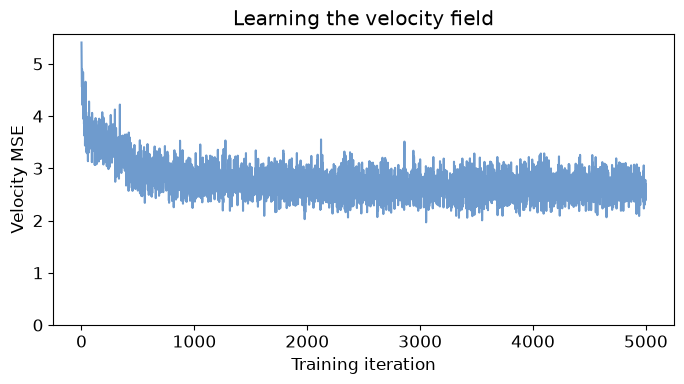

In [7]:
plt.plot(history, color="#2266B3", alpha=0.65)
plt.xlabel("Training iteration")
plt.ylabel("Velocity MSE")
plt.title("Learning the velocity field")
plt.ylim(bottom=0)
plt.tight_layout()
plt.savefig("figures/loss_curve.pdf")
plt.show()

## 5. Generate new samples by solving the ODE

We approximate the ODE with **forward Euler**. For $K$ steps, let $\Delta t=1/K$ and $t_k=k/K$:

$$X_{k+1}=X_k+\Delta t\,v_\theta(X_k,t_k),\qquad k=0,\ldots,K-1.$$

Notice the distinction: $K$ is the number of **sampling steps**, whereas 5,000 was the number of **training iterations**. The model parameters remain fixed during sampling. We use $K=100$ as the default and advance from $t=0$ to $t=1$ with a **plus** sign. We do not add random noise at every step: randomness enters through the initial Gaussian draw.

The function below accepts initial noise so we can reuse exactly the same points in a controlled step-size experiment. It also records positions for plotting. `no_grad()` is appropriate during generation because we are not learning parameters.

In [8]:
def generate(z, steps=100):
    x = z.clone()
    path = [x.clone()]
    with torch.no_grad():
        for k in range(steps):
            t = torch.full((len(x), 1), k / steps)
            x = x + model(torch.cat([x, t], dim=1)) / steps
            path.append(x.clone())
    return x, torch.stack(path)

We now draw 5,000 fresh Gaussian inputs and 5,000 independent target samples. They are created only after training. The real test samples are used for comparison, not inside the sampler. The fixed evaluation seed is different from the training seed.

In [9]:
torch.manual_seed(2026)
model.eval()
z = torch.randn(5000, 2)
real_test = sample_data(5000)
generated, path = generate(z)
print("Five new generated points:")
print(generated[:5])

Five new generated points:
tensor([[-1.6402,  2.0619],
        [ 1.9389,  1.5448],
        [-1.3625, -2.0082],
        [-2.2125, -1.1910],
        [-1.9082,  1.7470]])


These panels show the same 1,500 particles moving through generation time. Their final positions form the generated sample set. The generation function uses neither target centers nor real test samples.

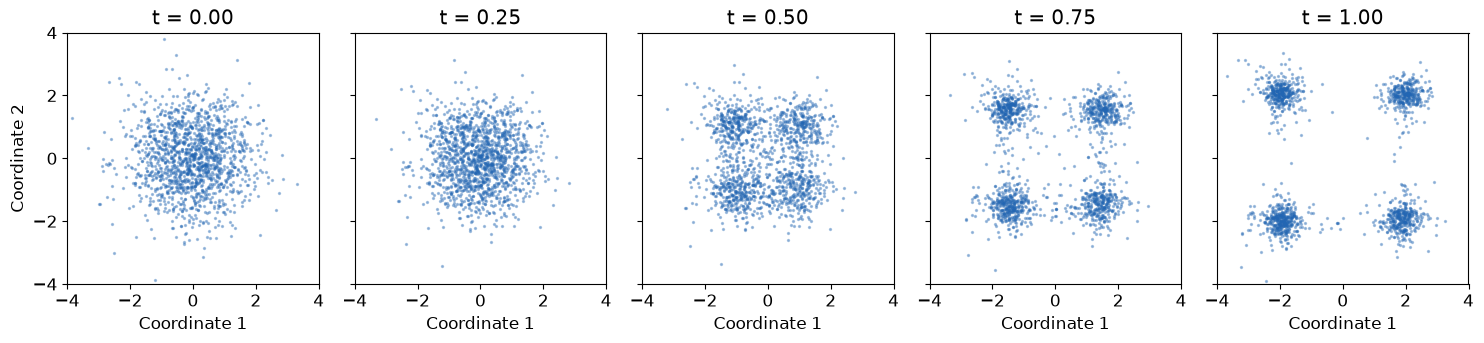

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharex=True, sharey=True)
for ax, index in zip(axes, [0, 25, 50, 75, 100]):
    points = path[index, :1500]
    ax.scatter(points[:, 0], points[:, 1], s=2, alpha=0.35, color="#2266B3")
    ax.set(title=f"t = {index / 100:.2f}", xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
    ax.set_xlabel("Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/generation_stages.pdf")
plt.show()

Here are 24 individual ODE trajectories. Open circles mark their starting points, and filled dots mark their endpoints. Colors identify which center is nearest to the endpoint. These are generated trajectories, not straight training interpolations.

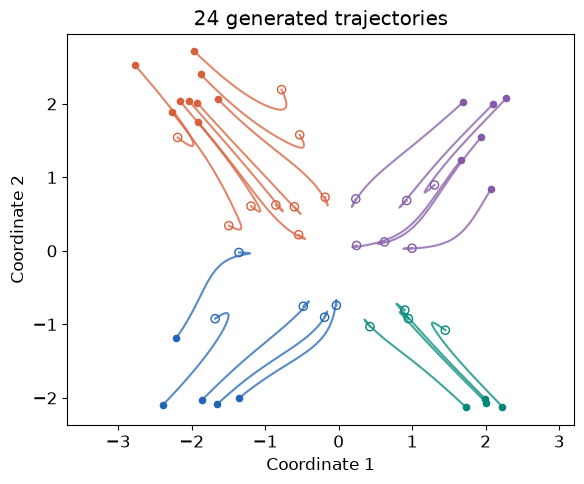

In [11]:
colors = ["#2266B3", "#D6603C", "#008878", "#8459A5"]
groups = torch.cdist(generated[:24], centers).argmin(dim=1)
plt.figure(figsize=(6, 5))
for j in range(24):
    points = path[:, j]
    color = colors[groups[j].item()]
    plt.plot(points[:, 0], points[:, 1], color=color, alpha=0.75)
    plt.scatter(*points[0], facecolors="none", edgecolors=color, s=35)
    plt.scatter(*points[-1], color=color, s=20)
plt.xlabel("Coordinate 1")
plt.ylabel("Coordinate 2")
plt.title("24 generated trajectories")
plt.axis("equal")
plt.tight_layout()
plt.savefig("figures/trajectories.pdf")
plt.show()

## 6. Compare the generated and target distributions

There is no paired correct endpoint for a new Gaussian input. We compare the whole sample distribution. The plots below use equal axes and show the first 2,000 points from each sample set.

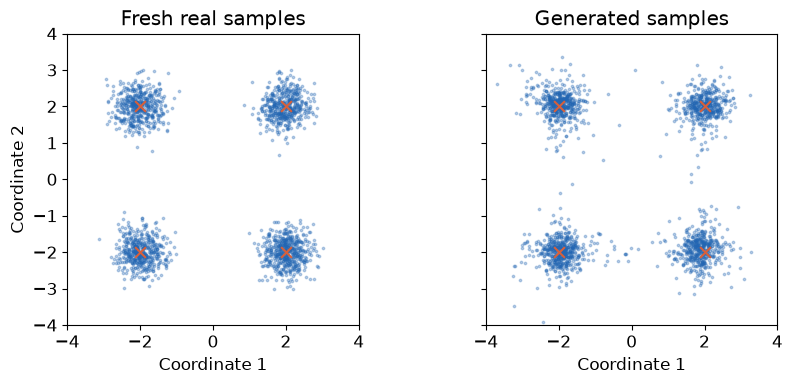

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, points, title in zip(axes, [real_test, generated], ["Fresh real samples", "Generated samples"]):
    ax.scatter(points[:2000, 0], points[:2000, 1], s=3, alpha=0.3, color="#2266B3")
    ax.scatter(centers[:, 0], centers[:, 1], marker="x", s=60, color="#D6603C")
    ax.set(title=title, xlim=(-4, 4), ylim=(-4, 4), aspect="equal", xlabel="Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/sample_comparison.pdf")
plt.show()

### Coverage and spread

We assign each point to its nearest center, then report the percentage assigned to each center. The target weights are 25% each; finite-sample frequencies vary. Nearest-center assignment is a diagnostic, not a recovered latent component label.

Counts alone can hide a bad generator: even four collapsed points could have the right proportions. We also measure the root mean squared distance to the nearest center and the percentage within distance 1 of a center. The latter is a chosen diagnostic threshold, not a confidence interval. Compare both quantities to fresh real samples. These checks still cannot certify complete distribution matching.

In [13]:
def summary(points):
    distance, group = torch.cdist(points, centers).min(dim=1)
    shares = 100 * torch.bincount(group, minlength=4) / len(points)
    radius = distance.square().mean().sqrt().reshape(1)
    nearby = 100 * (distance < 1).float().mean().reshape(1)
    return torch.cat([shares, radius, nearby])

print("Sample          C1%      C2%      C3%      C4%      RMSr    Near1%")
for name, points in [("Real test", real_test), ("Generated", generated)]:
    values = summary(points)
    print(f"{name:10s}" + "".join(f"{value:9.4f}" for value in values))

Sample          C1%      C2%      C3%      C4%      RMSr    Near1%
Real test   24.9000  24.3800  25.8600  24.8600   0.4934  98.4400
Generated   25.9800  25.8400  23.9600  24.2200   0.5187  95.2000


## 7. An experiment: fewer Euler steps

Use the same trained network and initial Gaussian points for 1, 10, and 100 steps. No retraining occurs. One large step follows only the initial velocity; smaller steps let the network respond to the changing position and time.

More steps usually reduce discretization error for a sufficiently regular field, but do not repair a poorly learned field. Visual quality and finite-sample metrics need not improve monotonically. We retain 100 as the preset default rather than selecting a checkpoint from these test results.

**Why does one step gather samples near the origin?** For the zero-mean target mixture, the ideal field at the start is $v^*(x,0)=\mathbb E[X_1]-x=-x$. One Euler step of size 1 therefore gives $x+(-x)=0$. A time-varying velocity must be reevaluated along the trajectory; its starting value is not a complete transport map.

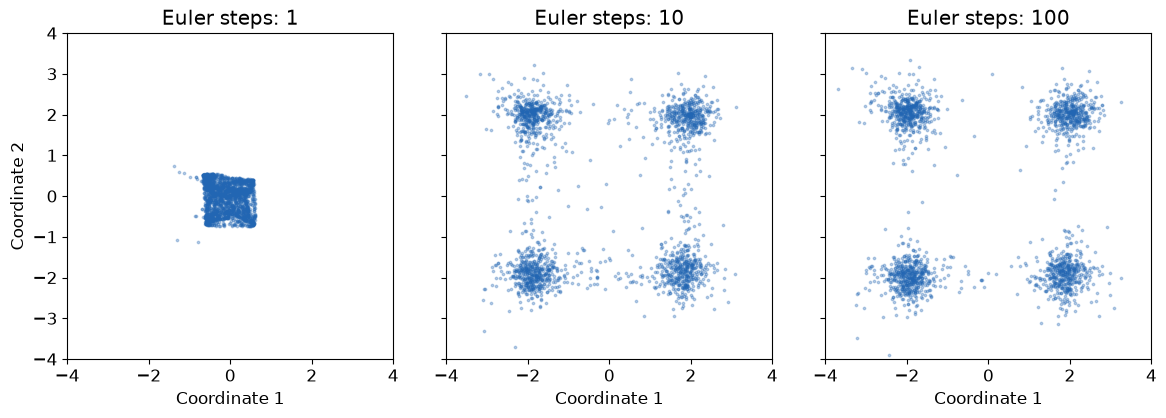

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, steps in zip(axes, [1, 10, 100]):
    points, _ = generate(z, steps)
    ax.scatter(points[:2000, 0], points[:2000, 1], s=3, alpha=0.3, color="#2266B3")
    ax.set(title=f"Euler steps: {steps}", xlim=(-4, 4), ylim=(-4, 4), aspect="equal")
    ax.set_xlabel("Coordinate 1")
axes[0].set_ylabel("Coordinate 2")
fig.tight_layout()
fig.savefig("figures/euler_steps.pdf")
plt.show()

## How does this connect to diffusion models?

In a score-based diffusion model, a forward **stochastic differential equation (SDE)** gradually adds noise to data. A model estimates the **score** $\nabla_x\log p_\tau(x)$. For state-independent scalar diffusion coefficient $g(\tau)$, the forward SDE and its associated probability-flow ODE are

$$dX=f(X,\tau)\,d\tau+g(\tau)\,dW_\tau,$$
$$\frac{dX}{d\tau}=f(X,\tau)-\frac12g(\tau)^2\nabla_x\log p_\tau(X).$$

Here $W_\tau$ is Brownian motion, which supplies random increments. Under the usual regularity assumptions and with the exact score, the SDE and this ODE have the same one-time marginal distributions, not the same sample paths. A diffusion sampler integrates this ODE backward from noise to data.

Our notebook uses the opposite time convention, with $t$ increasing from noise to data, and directly learns a velocity by flow matching. It does not estimate a score, simulate Brownian motion, or derive its velocity from that diffusion formula. Both approaches can generate via a time-dependent ODE; their training targets differ.

This is a small example in $\mathbb R^2$, not a time series generator. A later model could produce an entire vector of values along a time series, with evaluation that examines temporal dependence and, potentially, Volterra signatures.

## Student experiments

1. Change the training seed. Compare mode coverage and spread across runs.
2. Use 1,000 training iterations. Keep the default 100 Euler steps. Does a finer solver fix an undertrained network?
3. Change `sigma` from 0.35 to 0.15. The components become narrower. Update both training and test data by rerunning from the beginning.
4. Move the centers to a rectangle or use unequal mixture weights. Update the data sampler and evaluation explanations together.
5. Remove time from the model input and change `Linear(3, 64)` to `Linear(2, 64)`. Also remove time from the training and sampling concatenations. How does the fit change?

If experiments guide model choices, use separate validation data and reserve fresh samples for a final test. The preset final model is an approximation: finite data, a finite network, optimization, and Euler discretization all contribute error.

**References**

- Lipman et al., [Flow Matching for Generative Modeling](https://arxiv.org/abs/2210.02747), for conditional velocity regression and generative ODEs.
- Liu, Gong, and Liu, [Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow](https://arxiv.org/abs/2209.03003), for straight interpolation and least-squares velocity learning.
- Song et al., [Score-Based Generative Modeling through Stochastic Differential Equations](https://arxiv.org/abs/2011.13456), for the connection between diffusion SDEs and probability-flow ODEs.